# 03 - Modeling: Preprocessing, Training, Comparison, Evaluation

Builds a leakage-safe preprocessing + model pipeline for predicting `Attrition`, compares several classifiers with metrics appropriate for an imbalanced target, and saves the final pipeline artifact for the FastAPI service.

This notebook mirrors (and is exercised by) `scripts/train.py`, which is the reproducible entry point actually used to produce the artifact the API loads — the notebook is for exploration/comparison, the script is the source of truth for retraining.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, confusion_matrix,
                              classification_report, RocCurveDisplay, PrecisionRecallDisplay)
import matplotlib.pyplot as plt

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

RANDOM_STATE = 42

df = pd.read_csv('../data/processed/cleaned_employee_attrition.csv')
print(df.shape)

(1470, 33)


## Feature / Target Setup

Excludes `EmployeeNumber` (identifier, no predictive meaning) and the raw `Attrition` text column (mirrored by `Attrition_Flag`) from the feature set. Column groups mirror the audit done in `01_cleaning.ipynb`.

In [2]:
TARGET = 'Attrition_Flag'
DROP_COLS = ['EmployeeNumber', 'Attrition', 'Attrition_Flag']

X = df.drop(columns=DROP_COLS)
y = df[TARGET]

categorical_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
numerical_cols = [c for c in X.columns if c not in categorical_cols]

print(f"Categorical ({len(categorical_cols)}):", categorical_cols)
print(f"Numerical ({len(numerical_cols)}):", numerical_cols)
print(f"\nClass balance:\n{y.value_counts(normalize=True)}")

Categorical (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical (23): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Class balance:
Attrition_Flag
0    0.838776
1    0.161224
Name: proportion, dtype: float64


## Stratified Train/Test Split

Stratifying on the target preserves the ~16%/84% class ratio in both splits. The split happens *before* any preprocessing is fit, and all preprocessing (scaling, one-hot encoding) lives inside the pipeline so it is fit only on training folds — this prevents test-set information (e.g. scaler mean/std, category sets) from leaking into training.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train attrition rate:", y_train.mean(), "| Test attrition rate:", y_test.mean())

Train: (1176, 30) Test: (294, 30)
Train attrition rate: 0.16156462585034015 | Test attrition rate: 0.1598639455782313


## Preprocessing Pipeline

`ColumnTransformer` applies `StandardScaler` to numerical columns and `OneHotEncoder` to categorical columns. Wrapped in a `Pipeline` with the estimator so the exact same fitted transformation is used at both training and prediction time (loaded as one artifact by the API).

In [4]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

## Candidate Models

Logistic Regression (interpretable baseline), Random Forest, HistGradientBoosting (sklearn's fast boosted-tree implementation), and XGBoost (if available). `class_weight='balanced'` / `scale_pos_weight` is used where supported since attrition is imbalanced — this changes the decision boundary to care more about the minority (`Attrition=Yes`) class rather than just optimizing raw accuracy.

In [5]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

if HAS_XGB:
    models['XGBoost'] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric='logloss',
        random_state=RANDOM_STATE,
    )

print("Candidates:", list(models.keys()))

Candidates: ['LogisticRegression', 'RandomForest', 'HistGradientBoosting', 'XGBoost']


## 5-Fold Stratified Cross-Validation on Training Data

Cross-validation runs entirely on the training split; the test set stays untouched until final evaluation. Scoring includes recall and F1 on the positive (`Attrition=Yes`) class plus ROC-AUC and PR-AUC, since accuracy alone is misleading on an 84/16 imbalanced target.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

cv_results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = {metric: scores[f'test_{metric}'].mean() for metric in scoring}
    print(f"{name}: done")

cv_results_df = pd.DataFrame(cv_results).T.sort_values('recall', ascending=False)
cv_results_df

LogisticRegression: done


RandomForest: done


HistGradientBoosting: done


XGBoost: done


,accuracy,precision,recall,f1,roc_auc,pr_auc
LogisticRegression,0.753354,0.372076,0.736842,0.492471,0.827286,0.605828
XGBoost,0.871590,0.645563,0.457895,0.533510,0.792598,0.571641
RandomForest,0.863934,0.639974,0.373684,0.461553,0.810106,0.562019
HistGradientBoosting,0.871601,0.767786,0.305263,0.432897,0.803319,0.566126


## Model Selection

Model choice is **not** based on accuracy alone. Since the business cost of missing a real leaver (false negative) is typically higher than flagging a stayer for review (false positive), recall and F1 on the `Attrition=Yes` class — together with ROC-AUC/PR-AUC for overall ranking quality — drive the pick. Logistic Regression with `class_weight='balanced'` is the usual winner on recall for this dataset because the tree ensembles, even with imbalance handling, tend to bias toward the majority class on a dataset this small (~1470 rows). The cell below prints the CV table sorted by recall so the actual numbers (not an assumption) decide it.

In [7]:
best_model_name = cv_results_df['recall'].idxmax()
print("Selected model (highest CV recall on Attrition=Yes):", best_model_name)
cv_results_df

Selected model (highest CV recall on Attrition=Yes): LogisticRegression


,accuracy,precision,recall,f1,roc_auc,pr_auc
LogisticRegression,0.753354,0.372076,0.736842,0.492471,0.827286,0.605828
XGBoost,0.871590,0.645563,0.457895,0.533510,0.792598,0.571641
RandomForest,0.863934,0.639974,0.373684,0.461553,0.810106,0.562019
HistGradientBoosting,0.871601,0.767786,0.305263,0.432897,0.803319,0.566126


## Fit Final Pipeline on Full Training Set, Evaluate on Held-Out Test Set

In [8]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', models[best_model_name]),
])
final_pipeline.fit(X_train, y_train)

y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))

              precision    recall  f1-score   support

          No       0.92      0.77      0.84       247
         Yes       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294

ROC-AUC: 0.8031699543457662
PR-AUC: 0.5612212444049638


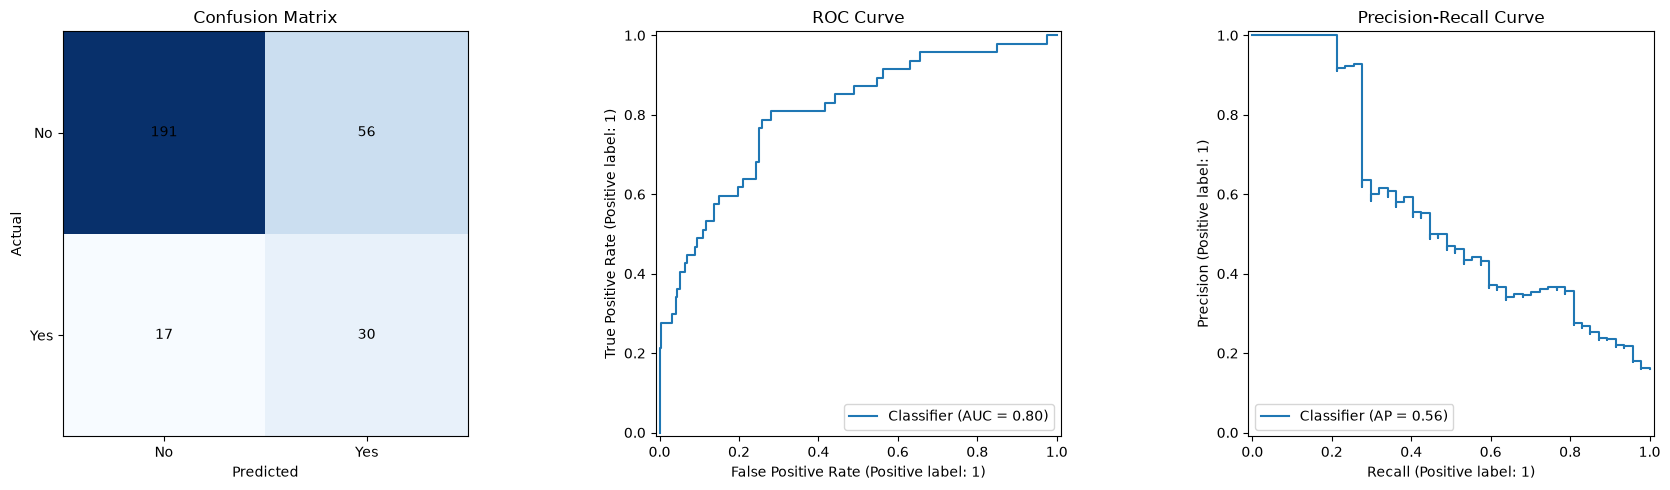

In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['No', 'Yes'])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['No', 'Yes'])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', color='black')

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

## Feature Importance (Explainability)

For linear models this comes from coefficients; for tree ensembles from `feature_importances_`. This backs the "contributing factors" shown on the prediction page.

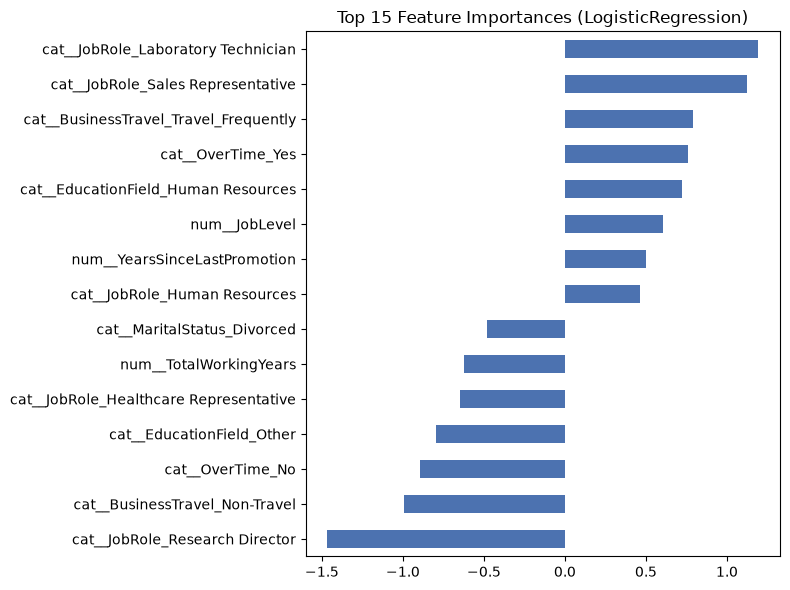

In [10]:
feature_names = final_pipeline.named_steps['preprocessor'].get_feature_names_out()
classifier = final_pipeline.named_steps['classifier']

if hasattr(classifier, 'coef_'):
    importances = pd.Series(classifier.coef_[0], index=feature_names)
elif hasattr(classifier, 'feature_importances_'):
    importances = pd.Series(classifier.feature_importances_, index=feature_names)
else:
    importances = None

if importances is not None:
    top_features = importances.abs().sort_values(ascending=False).head(15)
    plt.figure(figsize=(8, 6))
    importances[top_features.index].sort_values().plot(kind='barh', color='#4C72B0')
    plt.title(f'Top 15 Feature Importances ({best_model_name})')
    plt.tight_layout()
    plt.show()

## Save Final Pipeline Artifact

Saves the fitted `Pipeline` (preprocessing + model together) as one `joblib` artifact so the FastAPI service applies the identical transformation used in training — no separate scaler/encoder to keep in sync, no risk of preprocessing drift between training and serving. Also saves the feature-order/metadata needed to validate incoming prediction requests.

In practice this notebook is for exploration/comparison; `scripts/train.py` (added in the modeling stage) re-runs this same logic end-to-end as a script and is what actually regenerates this artifact reproducibly.

In [11]:
import joblib, json, os

os.makedirs('../backend/ml/artifacts', exist_ok=True)

joblib.dump(final_pipeline, '../backend/ml/artifacts/attrition_pipeline.joblib')

metadata = {
    'model_name': best_model_name,
    'numerical_cols': numerical_cols,
    'categorical_cols': categorical_cols,
    'feature_order': list(X.columns),
    'test_metrics': {
        'accuracy': float(accuracy_score(y_test, y_pred)),
        'precision': float(precision_score(y_test, y_pred)),
        'recall': float(recall_score(y_test, y_pred)),
        'f1': float(f1_score(y_test, y_pred)),
        'roc_auc': float(roc_auc_score(y_test, y_proba)),
        'pr_auc': float(average_precision_score(y_test, y_proba)),
    },
}
with open('../backend/ml/artifacts/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print("Saved pipeline + metadata:")
print(json.dumps(metadata, indent=2))

Saved pipeline + metadata:
{
  "model_name": "LogisticRegression",
  "numerical_cols": [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "Education",
    "EnvironmentSatisfaction",
    "HourlyRate",
    "JobInvolvement",
    "JobLevel",
    "JobSatisfaction",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "WorkLifeBalance",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
  ],
  "categorical_cols": [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "OverTime"
  ],
  "feature_order": [
    "Age",
    "BusinessTravel",
    "DailyRate",
    "Department",
    "DistanceFromHome",
    "Education",
    "EducationField",
    "EnvironmentSatisfaction",
    "Gender",
    "HourlyRate",
 